In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sarifasiddikatrina/isic-dicm/valid-set-metadata.csv
/kaggle/input/datasets/sarifasiddikatrina/isic-dicm/train-set-metadata.csv


In [3]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)
    for filename in filenames[:5]:
        print(" -", filename)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/sarifasiddikatrina
/kaggle/input/datasets/sarifasiddikatrina/isic-dicm
 - valid-set-metadata.csv
 - train-set-metadata.csv


In [4]:
import requests
import pandas as pd
import os

df = pd.read_csv('/kaggle/input/datasets/sarifasiddikatrina/isic-dicm/train-set-metadata.csv')
mel = df[df['class'] == 1].sample(n=2000, random_state=42)
non_mel = df[df['class'] == 0].sample(n=2000, random_state=42)
subset = pd.concat([mel, non_mel]).reset_index(drop=True)

os.makedirs('/kaggle/working/images', exist_ok=True)

failed = []
for i, row in subset.iterrows():
    isic_id = row['isic_id']
    save_path = f"/kaggle/working/images/{isic_id}.jpg"
    if os.path.exists(save_path):
        continue
    try:
        meta_resp = requests.get(f"https://api.isic-archive.com/api/v2/images/{isic_id}/", timeout=10)
        img_url = meta_resp.json()['files']['full']['url']
        img_data = requests.get(img_url, timeout=10).content
        with open(save_path, 'wb') as f:
            f.write(img_data)
    except Exception as e:
        failed.append(isic_id)
    if i % 200 == 0:
        print(f"Progress: {i}/{len(subset)}")

subset.to_csv('/kaggle/working/subset_metadata.csv', index=False)
print("Done. Failed:", len(failed))

Progress: 0/4000
Progress: 200/4000
Progress: 400/4000
Progress: 600/4000
Progress: 800/4000
Progress: 1000/4000
Progress: 1200/4000
Progress: 1400/4000
Progress: 1600/4000
Progress: 1800/4000
Progress: 2000/4000
Progress: 2200/4000
Progress: 2400/4000
Progress: 2600/4000
Progress: 2800/4000
Progress: 3000/4000
Progress: 3200/4000
Progress: 3400/4000
Progress: 3600/4000
Progress: 3800/4000
Done. Failed: 0


In [9]:
subset = pd.read_csv('/kaggle/working/subset_metadata.csv')
subset['patient_id'] = subset['patient_id'].astype(str)
subset.loc[subset['patient_id'] == 'nan', 'patient_id'] = 'unknown_' + subset.index[subset['patient_id'] == 'nan'].astype(str)

sgkf1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
trainval_idx, test_idx = next(sgkf1.split(subset, subset['class'], groups=subset['patient_id']))
trainval_df = subset.iloc[trainval_idx].reset_index(drop=True)
test_df = subset.iloc[test_idx].reset_index(drop=True)

sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
train_idx, val_idx = next(sgkf2.split(trainval_df, trainval_df['class'], groups=trainval_df['patient_id']))
train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
val_df = trainval_df.iloc[val_idx].reset_index(drop=True)

print("Overlap check:", len(set(train_df['patient_id']) & set(test_df['patient_id'])))
print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))
print(train_df['class'].value_counts())

Overlap check: 0
Train: 2849 Val: 578 Test: 573
class
0    1426
1    1423
Name: count, dtype: int64


In [10]:
cat_cols = ['sex', 'anatom_site_general', 'dermoscopic_type', 'diagnosis_confirm_type', 'melanocytic']
numeric_cols = ['age_approx', 'clin_size_long_diam_mm']

for col in cat_cols:
    train_df[col] = train_df[col].astype(str)
    val_df[col] = val_df[col].astype(str)
    test_df[col] = test_df[col].astype(str)

def encode_metadata(df, cat_cols, numeric_cols, reference_columns=None):
    df_cat = pd.get_dummies(df[cat_cols].astype(str))
    df_num = df[numeric_cols].fillna(df[numeric_cols].median())
    df_encoded = pd.concat([df_num, df_cat], axis=1)
    if reference_columns is not None:
        df_encoded = df_encoded.reindex(columns=reference_columns, fill_value=0)
    return df_encoded

full_ref_columns = encode_metadata(subset, cat_cols, numeric_cols).columns
META_DIM = len(full_ref_columns)

train_meta = encode_metadata(train_df, cat_cols, numeric_cols, reference_columns=full_ref_columns)
val_meta = encode_metadata(val_df, cat_cols, numeric_cols, reference_columns=full_ref_columns)
test_meta = encode_metadata(test_df, cat_cols, numeric_cols, reference_columns=full_ref_columns)

le = LabelEncoder()
le.fit(train_df['class'])
train_labels = le.transform(train_df['class'])
val_labels = le.transform(val_df['class'])
test_labels = le.transform(test_df['class'])

print("META_DIM:", META_DIM)
print("Classes:", le.classes_)

META_DIM: 26
Classes: [0 1]


In [12]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms
import torchvision.models as models
import os

class SkinFusionDataset(Dataset):
    def __init__(self, df, meta_features, labels, image_folders, transform=None):
        self.df = df.reset_index(drop=True)
        self.meta_features = meta_features.reset_index(drop=True)
        self.labels = labels
        self.transform = transform
        self.image_lookup = {}
        for folder in image_folders:
            for fname in os.listdir(folder):
                self.image_lookup[fname] = os.path.join(folder, fname)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.loc[idx, 'img_id']
        img_path = self.image_lookup[img_name]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        meta = torch.tensor(self.meta_features.iloc[idx].values.astype('float32'))
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, meta, label

transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
train_transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(), transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2), transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


In [13]:
train_df['img_id'] = train_df['isic_id'] + '.jpg'
val_df['img_id'] = val_df['isic_id'] + '.jpg'
test_df['img_id'] = test_df['isic_id'] + '.jpg'

image_folders = ['/kaggle/working/images']

train_dataset = SkinFusionDataset(train_df, train_meta, train_labels, image_folders, train_transform)
val_dataset = SkinFusionDataset(val_df, val_meta, val_labels, image_folders, transform)
test_dataset = SkinFusionDataset(test_df, test_meta, test_labels, image_folders, transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

images, metas, labels = next(iter(train_loader))
print("Batch shapes:", images.shape, metas.shape, labels.shape)

Batch shapes: torch.Size([32, 3, 224, 224]) torch.Size([32, 26]) torch.Size([32])


In [15]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, metas, labels in loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images, metas)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / len(loader), correct / total

def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)
            outputs = model(images, metas)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return total_loss / len(loader), correct / total

class FusionModel(nn.Module):
    def __init__(self, meta_input_dim, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer3' not in name and 'layer4' not in name:
                param.requires_grad = False
        self.meta_branch = nn.Sequential(nn.Linear(meta_input_dim, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU())
        self.classifier = nn.Sequential(nn.Linear(512+32, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, num_classes))

    def forward(self, image, meta):
        img_feat = self.image_branch(image).flatten(1)
        meta_feat = self.meta_branch(meta)
        return self.classifier(torch.cat([img_feat, meta_feat], dim=1))

torch.manual_seed(42)
np.random.seed(42)
torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

class_weights = torch.tensor(compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

model = FusionModel(meta_input_dim=META_DIM, num_classes=2).to(device)
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4, weight_decay=1e-4)

history_fusion = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0
for epoch in range(15):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    history_fusion['train_loss'].append(train_loss); history_fusion['val_loss'].append(val_loss)
    history_fusion['train_acc'].append(train_acc); history_fusion['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/15 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/kaggle/working/best_model_isic.pth')
        print("  -> Saved new best model")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 186MB/s] 


Epoch 1/15 - Train loss: 0.6784, Train acc: 0.5725 - Val loss: 0.6406, Val acc: 0.6644
  -> Saved new best model
Epoch 2/15 - Train loss: 0.6262, Train acc: 0.6627 - Val loss: 0.6035, Val acc: 0.7145
  -> Saved new best model
Epoch 3/15 - Train loss: 0.5987, Train acc: 0.6802 - Val loss: 0.5798, Val acc: 0.7042
Epoch 4/15 - Train loss: 0.5790, Train acc: 0.6837 - Val loss: 0.5670, Val acc: 0.7042
Epoch 5/15 - Train loss: 0.5680, Train acc: 0.7055 - Val loss: 0.5513, Val acc: 0.7284
  -> Saved new best model
Epoch 6/15 - Train loss: 0.5627, Train acc: 0.7009 - Val loss: 0.5720, Val acc: 0.7024
Epoch 7/15 - Train loss: 0.5538, Train acc: 0.7045 - Val loss: 0.5637, Val acc: 0.7007
Epoch 8/15 - Train loss: 0.5502, Train acc: 0.7220 - Val loss: 0.5370, Val acc: 0.7284
Epoch 9/15 - Train loss: 0.5509, Train acc: 0.7248 - Val loss: 0.5212, Val acc: 0.7491
  -> Saved new best model
Epoch 10/15 - Train loss: 0.5373, Train acc: 0.7210 - Val loss: 0.5230, Val acc: 0.7388
Epoch 11/15 - Train loss:

In [16]:
model.load_state_dict(torch.load('/kaggle/working/best_model_isic.pth'))
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Fusion Test acc: {test_acc:.4f}")

Fusion Test acc: 0.7330


In [19]:
class ImageOnlyModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer3' not in name and 'layer4' not in name:
                param.requires_grad = False
        self.classifier = nn.Sequential(nn.Linear(512, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, num_classes))
    def forward(self, image, meta=None):
        return self.classifier(self.image_branch(image).flatten(1))

torch.manual_seed(42)
np.random.seed(42)
torch.cuda.manual_seed_all(42)

img_model = ImageOnlyModel(num_classes=2).to(device)
img_optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, img_model.parameters()), lr=1e-4, weight_decay=1e-4)

history_img = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0
for epoch in range(15):
    train_loss, train_acc = train_one_epoch(img_model, train_loader, criterion, img_optimizer, device)
    val_loss, val_acc = evaluate(img_model, val_loader, criterion, device)
    history_img['train_loss'].append(train_loss); history_img['val_loss'].append(val_loss)
    history_img['train_acc'].append(train_acc); history_img['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/15 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(img_model.state_dict(), '/kaggle/working/best_image_only_isic.pth')
        print("  -> Saved new best model")

Epoch 1/15 - Train loss: 0.6728, Train acc: 0.5830 - Val loss: 0.6378, Val acc: 0.6713
  -> Saved new best model
Epoch 2/15 - Train loss: 0.6335, Train acc: 0.6550 - Val loss: 0.6170, Val acc: 0.6920
  -> Saved new best model
Epoch 3/15 - Train loss: 0.6090, Train acc: 0.6680 - Val loss: 0.5901, Val acc: 0.7076
  -> Saved new best model
Epoch 4/15 - Train loss: 0.6032, Train acc: 0.6753 - Val loss: 0.5860, Val acc: 0.7215
  -> Saved new best model
Epoch 5/15 - Train loss: 0.5894, Train acc: 0.6866 - Val loss: 0.6042, Val acc: 0.7007
Epoch 6/15 - Train loss: 0.5960, Train acc: 0.6848 - Val loss: 0.5764, Val acc: 0.7197
Epoch 7/15 - Train loss: 0.5915, Train acc: 0.6866 - Val loss: 0.5683, Val acc: 0.7197
Epoch 8/15 - Train loss: 0.5780, Train acc: 0.6869 - Val loss: 0.5875, Val acc: 0.7163
Epoch 9/15 - Train loss: 0.5709, Train acc: 0.6964 - Val loss: 0.5605, Val acc: 0.7370
  -> Saved new best model
Epoch 10/15 - Train loss: 0.5681, Train acc: 0.6988 - Val loss: 0.5869, Val acc: 0.7163

In [20]:
class MetaOnlyModel(nn.Module):
    def __init__(self, meta_input_dim, num_classes):
        super().__init__()
        self.meta_branch = nn.Sequential(nn.Linear(meta_input_dim, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU())
        self.classifier = nn.Sequential(nn.Linear(32, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, num_classes))
    def forward(self, image, meta):
        return self.classifier(self.meta_branch(meta))

torch.manual_seed(42); np.random.seed(42); torch.cuda.manual_seed_all(42)
meta_model = MetaOnlyModel(meta_input_dim=META_DIM, num_classes=2).to(device)
meta_optimizer = torch.optim.Adam(meta_model.parameters(), lr=1e-4, weight_decay=1e-4)

history_meta = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0
for epoch in range(15):
    train_loss, train_acc = train_one_epoch(meta_model, train_loader, criterion, meta_optimizer, device)
    val_loss, val_acc = evaluate(meta_model, val_loader, criterion, device)
    history_meta['train_loss'].append(train_loss); history_meta['val_loss'].append(val_loss)
    history_meta['train_acc'].append(train_acc); history_meta['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/15 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(meta_model.state_dict(), '/kaggle/working/best_meta_only_isic.pth')
        print("  -> Saved new best model")

Epoch 1/15 - Train loss: 0.6996, Train acc: 0.5177 - Val loss: 0.6767, Val acc: 0.5813
  -> Saved new best model
Epoch 2/15 - Train loss: 0.6825, Train acc: 0.5570 - Val loss: 0.6743, Val acc: 0.6003
  -> Saved new best model
Epoch 3/15 - Train loss: 0.6854, Train acc: 0.5602 - Val loss: 0.6713, Val acc: 0.6211
  -> Saved new best model
Epoch 4/15 - Train loss: 0.6819, Train acc: 0.5683 - Val loss: 0.6670, Val acc: 0.6211
Epoch 5/15 - Train loss: 0.6782, Train acc: 0.5869 - Val loss: 0.6629, Val acc: 0.6315
  -> Saved new best model
Epoch 6/15 - Train loss: 0.6726, Train acc: 0.5963 - Val loss: 0.6554, Val acc: 0.6626
  -> Saved new best model
Epoch 7/15 - Train loss: 0.6655, Train acc: 0.6206 - Val loss: 0.6473, Val acc: 0.6851
  -> Saved new best model
Epoch 8/15 - Train loss: 0.6559, Train acc: 0.6458 - Val loss: 0.6377, Val acc: 0.6609
Epoch 9/15 - Train loss: 0.6463, Train acc: 0.6634 - Val loss: 0.6251, Val acc: 0.6972
  -> Saved new best model
Epoch 10/15 - Train loss: 0.6281, T

In [21]:
class MetaBlock(nn.Module):
    def __init__(self, image_feat_dim, meta_input_dim, num_classes):
        super().__init__()
        resnet = models.resnet18(weights='IMAGENET1K_V1')
        self.image_branch = nn.Sequential(*list(resnet.children())[:-1])
        for name, param in self.image_branch.named_parameters():
            if 'layer3' not in name and 'layer4' not in name:
                param.requires_grad = False
        self.meta_gate = nn.Sequential(nn.Linear(meta_input_dim, image_feat_dim), nn.Sigmoid())
        self.meta_bias = nn.Sequential(nn.Linear(meta_input_dim, image_feat_dim), nn.Tanh())
        self.classifier = nn.Sequential(nn.Linear(image_feat_dim, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, num_classes))
    def forward(self, image, meta):
        img_feat = self.image_branch(image).flatten(1)
        gate = self.meta_gate(meta)
        bias = self.meta_bias(meta)
        return self.classifier(img_feat * gate + bias)

torch.manual_seed(42); np.random.seed(42); torch.cuda.manual_seed_all(42)
metablock_model = MetaBlock(image_feat_dim=512, meta_input_dim=META_DIM, num_classes=2).to(device)
metablock_optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, metablock_model.parameters()), lr=1e-4, weight_decay=1e-4)

history_mb = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0
for epoch in range(20):
    train_loss, train_acc = train_one_epoch(metablock_model, train_loader, criterion, metablock_optimizer, device)
    val_loss, val_acc = evaluate(metablock_model, val_loader, criterion, device)
    history_mb['train_loss'].append(train_loss); history_mb['val_loss'].append(val_loss)
    history_mb['train_acc'].append(train_acc); history_mb['val_acc'].append(val_acc)
    print(f"Epoch {epoch+1}/20 - Train loss: {train_loss:.4f}, Train acc: {train_acc:.4f} - Val loss: {val_loss:.4f}, Val acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(metablock_model.state_dict(), '/kaggle/working/best_metablock_isic.pth')
        print("  -> Saved new best model")

Epoch 1/20 - Train loss: 0.6713, Train acc: 0.5844 - Val loss: 0.6285, Val acc: 0.6747
  -> Saved new best model
Epoch 2/20 - Train loss: 0.6237, Train acc: 0.6634 - Val loss: 0.5820, Val acc: 0.7128
  -> Saved new best model
Epoch 3/20 - Train loss: 0.5924, Train acc: 0.6894 - Val loss: 0.5727, Val acc: 0.6851
Epoch 4/20 - Train loss: 0.5775, Train acc: 0.6922 - Val loss: 0.5374, Val acc: 0.7059
Epoch 5/20 - Train loss: 0.5489, Train acc: 0.7146 - Val loss: 0.5239, Val acc: 0.7093
Epoch 6/20 - Train loss: 0.5430, Train acc: 0.7206 - Val loss: 0.4930, Val acc: 0.7526
  -> Saved new best model
Epoch 7/20 - Train loss: 0.5271, Train acc: 0.7259 - Val loss: 0.4838, Val acc: 0.7526
Epoch 8/20 - Train loss: 0.5139, Train acc: 0.7339 - Val loss: 0.4725, Val acc: 0.7595
  -> Saved new best model
Epoch 9/20 - Train loss: 0.5021, Train acc: 0.7501 - Val loss: 0.4578, Val acc: 0.7578
Epoch 10/20 - Train loss: 0.4860, Train acc: 0.7666 - Val loss: 0.4498, Val acc: 0.7647
  -> Saved new best model

In [23]:
from scipy.stats import spearmanr

model.load_state_dict(torch.load('/kaggle/working/best_model_isic.pth'))

def compute_ablation_importance(model, loader, device):
    model.eval()
    results = {'true_label': [], 'baseline_prob': [], 'no_image_prob': [], 'no_meta_prob': [], 'none_prob': []}
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)
            baseline_out = torch.softmax(model(images, metas), dim=1)
            zero_images = torch.zeros_like(images)
            no_image_out = torch.softmax(model(zero_images, metas), dim=1)
            zero_metas = torch.zeros_like(metas)
            no_meta_out = torch.softmax(model(images, zero_metas), dim=1)
            none_out = torch.softmax(model(zero_images, zero_metas), dim=1)
            for i in range(labels.size(0)):
                label = labels[i].item()
                results['true_label'].append(label)
                results['baseline_prob'].append(baseline_out[i, label].item())
                results['no_image_prob'].append(no_image_out[i, label].item())
                results['no_meta_prob'].append(no_meta_out[i, label].item())
                results['none_prob'].append(none_out[i, label].item())
    return pd.DataFrame(results)

ablation_df = compute_ablation_importance(model, test_loader, device)
ablation_df['image_importance'] = ablation_df['baseline_prob'] - ablation_df['no_image_prob']
ablation_df['shapley_image'] = 0.5*(ablation_df['no_meta_prob']-ablation_df['none_prob']) + 0.5*(ablation_df['baseline_prob']-ablation_df['no_image_prob'])

corr_shap, p_shap = spearmanr(ablation_df['image_importance'], ablation_df['shapley_image'])
print(ablation_df[['image_importance']].describe())
print(f"\nAblation vs Shapley: rho={corr_shap:.3f}, p={p_shap:.4f}")

       image_importance
count        573.000000
mean           0.096695
std            0.203572
min           -0.485274
25%           -0.036779
50%            0.136184
75%            0.255545
max            0.502553

Ablation vs Shapley: rho=0.988, p=0.0000


In [24]:
!pip install captum -q
from captum.attr import IntegratedGradients

def compute_ig_importance(model, loader, device):
    model.eval()
    ig_image_scores = []
    def forward_func(images, metas):
        return model(images, metas)
    ig = IntegratedGradients(forward_func)
    for images, metas, labels in loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        images.requires_grad_(); metas.requires_grad_()
        for i in range(labels.size(0)):
            attributions = ig.attribute((images[i:i+1], metas[i:i+1]), target=labels[i].item(), n_steps=20)
            img_attr, _ = attributions
            ig_image_scores.append(img_attr.abs().sum().item())
    return ig_image_scores

ig_image = compute_ig_importance(model, test_loader, device)
ablation_df['ig_image'] = ig_image
corr_ig, p_ig = spearmanr(ablation_df['image_importance'], ablation_df['ig_image'])
print(f"Ablation vs IG: rho={corr_ig:.3f}, p={p_ig:.4f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 9.1 MB/s eta 0:00:00ta 0:00:01
Ablation vs IG: rho=0.100, p=0.0165


In [25]:
img_model.load_state_dict(torch.load('/kaggle/working/best_image_only_isic.pth'))
_, img_test_acc = evaluate(img_model, test_loader, criterion, device)
print(f"Image-only Test acc: {img_test_acc:.4f}")

meta_model.load_state_dict(torch.load('/kaggle/working/best_meta_only_isic.pth'))
_, meta_test_acc = evaluate(meta_model, test_loader, criterion, device)
print(f"Meta-only Test acc: {meta_test_acc:.4f}")

metablock_model.load_state_dict(torch.load('/kaggle/working/best_metablock_isic.pth'))
_, mb_test_acc = evaluate(metablock_model, test_loader, criterion, device)
print(f"MetaBlock Test acc: {mb_test_acc:.4f}")

Image-only Test acc: 0.6894
Meta-only Test acc: 0.7382
MetaBlock Test acc: 0.7609


In [26]:
def make_truly_random_model(meta_input_dim, num_classes):
    m = FusionModel(meta_input_dim=meta_input_dim, num_classes=num_classes)
    for module in m.image_branch.modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            nn.init.kaiming_normal_(module.weight)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.BatchNorm2d):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)
    return m.to(device)

random_model = make_truly_random_model(meta_input_dim=META_DIM, num_classes=2)
random_ig_image = compute_ig_importance(random_model, test_loader, device)
corr_sanity, p_sanity = spearmanr(ig_image, random_ig_image)
print(f"Trained-IG vs Random-IG: rho={corr_sanity:.3f}, p={p_sanity:.4f}")

Trained-IG vs Random-IG: rho=0.604, p=0.0000


In [36]:
def compute_gate_importance(mb_model, loader, device):
    mb_model.eval()
    gate_scores = []
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas = images.to(device), metas.to(device)
            gate = mb_model.meta_gate(metas)
            gate_scores.extend(gate.mean(dim=1).cpu().numpy())
    return gate_scores

gate_scores = compute_gate_importance(metablock_model, test_loader, device)
ablation_df['gate_image'] = gate_scores
corr_gate, p_gate = spearmanr(ablation_df['image_importance'], ablation_df['gate_image'])
print(f"Ablation vs Gate: rho={corr_gate:.3f}, p={p_gate:.4f}")
print(ablation_df['gate_image'].describe())

Ablation vs Gate: rho=-0.317, p=0.0000
count    573.000000
mean       0.532539
std        0.001902
min        0.527306
25%        0.531248
50%        0.532497
75%        0.533901
max        0.548033
Name: gate_image, dtype: float64


In [37]:
from sklearn.metrics import classification_report

def get_report(m, loader, device, is_image_only=False, is_meta_only=False):
    m.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, metas, labels in loader:
            images, metas, labels = images.to(device), metas.to(device), labels.to(device)
            if is_image_only:
                outputs = m(images)
            else:
                outputs = m(images, metas)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    print(classification_report(all_labels, all_preds, target_names=['non-MEL', 'MEL'], zero_division=0))

print("Fusion:")
get_report(model, test_loader, device)

print("\nImage-only:")
get_report(img_model, test_loader, device, is_image_only=True)

print("\nMeta-only:")
get_report(meta_model, test_loader, device)

print("\nMetaBlock:")
get_report(metablock_model, test_loader, device)

Fusion:
              precision    recall  f1-score   support

     non-MEL       0.73      0.79      0.76       300
         MEL       0.74      0.67      0.71       273

    accuracy                           0.73       573
   macro avg       0.73      0.73      0.73       573
weighted avg       0.73      0.73      0.73       573


Image-only:
              precision    recall  f1-score   support

     non-MEL       0.73      0.65      0.69       300
         MEL       0.66      0.73      0.69       273

    accuracy                           0.69       573
   macro avg       0.69      0.69      0.69       573
weighted avg       0.69      0.69      0.69       573


Meta-only:
              precision    recall  f1-score   support

     non-MEL       0.79      0.68      0.73       300
         MEL       0.69      0.81      0.75       273

    accuracy                           0.74       573
   macro avg       0.74      0.74      0.74       573
weighted avg       0.75      0.74      0.

In [38]:
ablation_df['rank_ablation'] = ablation_df['image_importance'].rank()
ablation_df['rank_ig'] = ablation_df['ig_image'].rank()
ablation_df['rank_gate'] = ablation_df['gate_image'].rank()
ablation_df['ig_disagreement'] = (ablation_df['rank_ablation'] - ablation_df['rank_ig']).abs()
ablation_df['gate_disagreement'] = (ablation_df['rank_ablation'] - ablation_df['rank_gate']).abs()

print("Top IG disagreement:")
print(ablation_df.nlargest(3, 'ig_disagreement')[['true_label','rank_ablation','rank_ig','image_importance','ig_image']])

print("\nTop Gate disagreement:")
print(ablation_df.nlargest(3, 'gate_disagreement')[['true_label','rank_ablation','rank_gate','image_importance','gate_image']])

Top IG disagreement:
     true_label  rank_ablation  rank_ig  image_importance     ig_image
371           0          571.0     26.0          0.483969   259.100464
125           1           19.0    563.0         -0.329999  1186.378662
288           0          550.0      8.0          0.385308   196.138794

Top Gate disagreement:
     true_label  rank_ablation  rank_gate  image_importance  gate_image
61            1            7.0      567.0         -0.415311    0.536317
144           1            4.0      559.5         -0.434267    0.535670
288           0          550.0       11.0          0.385308    0.528564


In [39]:
from sklearn.utils import resample

n_bootstrap = 1000
bootstrap_means = []
for _ in range(n_bootstrap):
    sample = resample(ablation_df['image_importance'], n_samples=len(ablation_df))
    bootstrap_means.append(sample.mean())

ci_lower = np.percentile(bootstrap_means, 2.5)
ci_upper = np.percentile(bootstrap_means, 97.5)
print(f"Ablation image_importance mean: {ablation_df['image_importance'].mean():.4f}")
print(f"95% CI: [{ci_lower:.4f}, {ci_upper:.4f}]")

Ablation image_importance mean: 0.0967
95% CI: [0.0810, 0.1120]


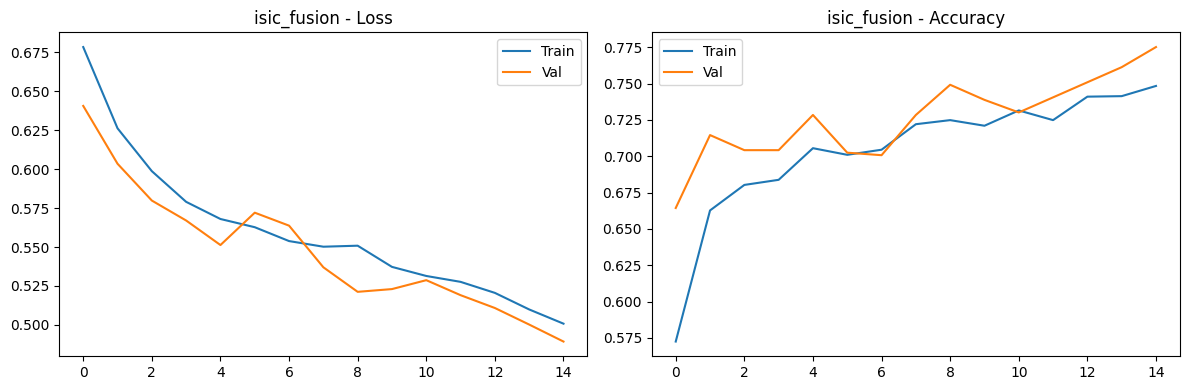

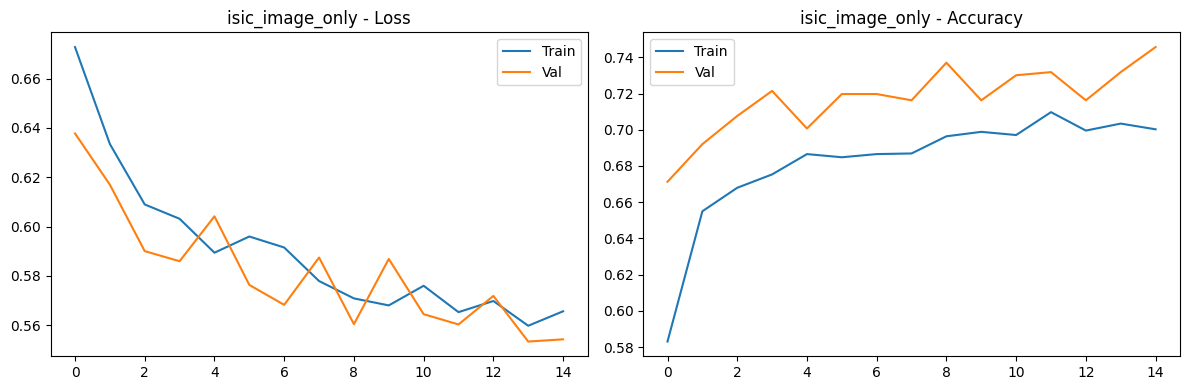

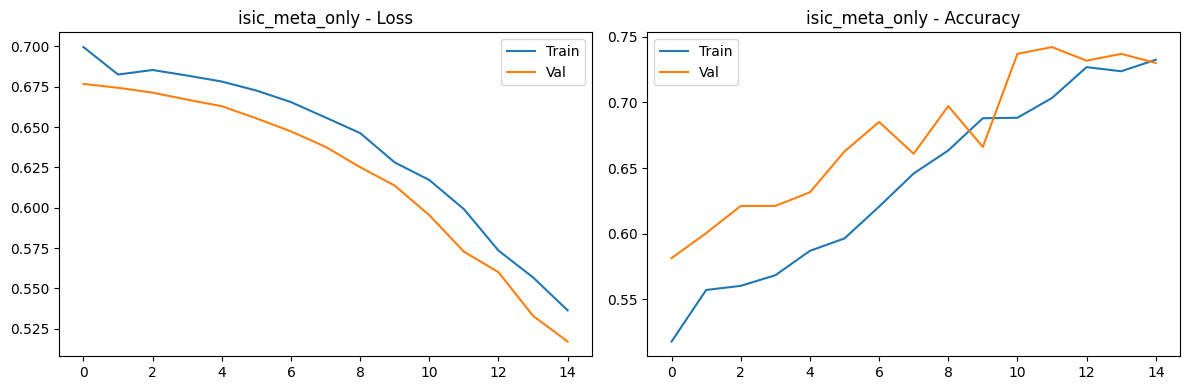

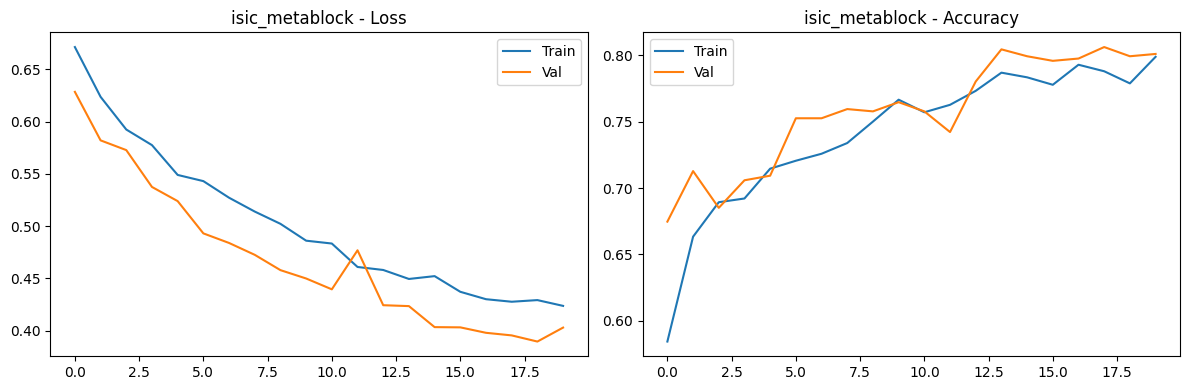

In [40]:
import matplotlib.pyplot as plt

def plot_curves(train_loss, val_loss, train_acc, val_acc, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(train_loss, label='Train'); axes[0].plot(val_loss, label='Val')
    axes[0].set_title(f'{title} - Loss'); axes[0].legend()
    axes[1].plot(train_acc, label='Train'); axes[1].plot(val_acc, label='Val')
    axes[1].set_title(f'{title} - Accuracy'); axes[1].legend()
    plt.tight_layout()
    plt.savefig(f'/kaggle/working/curve_{title}.png')
    plt.show()

plot_curves(history_fusion['train_loss'], history_fusion['val_loss'], history_fusion['train_acc'], history_fusion['val_acc'], 'isic_fusion')
plot_curves(history_img['train_loss'], history_img['val_loss'], history_img['train_acc'], history_img['val_acc'], 'isic_image_only')
plot_curves(history_meta['train_loss'], history_meta['val_loss'], history_meta['train_acc'], history_meta['val_acc'], 'isic_meta_only')
plot_curves(history_mb['train_loss'], history_mb['val_loss'], history_mb['train_acc'], history_mb['val_acc'], 'isic_metablock')

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

results_10runs_isic = []

for seed in range(1, 11):
    print(f"\n===== SEED {seed} (new split + new weights) =====")
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed_all(seed)

    sgkf1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
    trainval_idx, test_idx = next(sgkf1.split(subset, subset['class'], groups=subset['patient_id']))
    trainval_df_s = subset.iloc[trainval_idx].reset_index(drop=True)
    test_df_s = subset.iloc[test_idx].reset_index(drop=True)

    sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=seed)
    train_idx, val_idx = next(sgkf2.split(trainval_df_s, trainval_df_s['class'], groups=trainval_df_s['patient_id']))
    train_df_s = trainval_df_s.iloc[train_idx].reset_index(drop=True)
    val_df_s = trainval_df_s.iloc[val_idx].reset_index(drop=True)

    for df_ in [train_df_s, val_df_s, test_df_s]:
        df_['img_id'] = df_['isic_id'] + '.jpg'

    train_meta_s = encode_metadata(train_df_s, cat_cols, numeric_cols, reference_columns=full_ref_columns)
    test_meta_s = encode_metadata(test_df_s, cat_cols, numeric_cols, reference_columns=full_ref_columns)

    le_s = LabelEncoder()
    le_s.fit(train_df_s['class'])
    train_labels_s = le_s.transform(train_df_s['class'])
    test_labels_s = le_s.transform(test_df_s['class'])

    train_dataset_s = SkinFusionDataset(train_df_s, train_meta_s, train_labels_s, image_folders, train_transform)
    test_dataset_s = SkinFusionDataset(test_df_s, test_meta_s, test_labels_s, image_folders, transform)
    train_loader_s = DataLoader(train_dataset_s, batch_size=32, shuffle=True, num_workers=2)
    test_loader_s = DataLoader(test_dataset_s, batch_size=32, shuffle=False, num_workers=2)

    class_weights_s = torch.tensor(compute_class_weight('balanced', classes=np.unique(train_labels_s), y=train_labels_s), dtype=torch.float32).to(device)
    criterion_s = nn.CrossEntropyLoss(weight=class_weights_s)

    m = FusionModel(meta_input_dim=META_DIM, num_classes=2).to(device)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=1e-4, weight_decay=1e-4)
    for epoch in range(15):
        train_one_epoch(m, train_loader_s, criterion_s, opt, device)

    mb = MetaBlock(image_feat_dim=512, meta_input_dim=META_DIM, num_classes=2).to(device)
    mb_opt = torch.optim.Adam(filter(lambda p: p.requires_grad, mb.parameters()), lr=1e-4, weight_decay=1e-4)
    for epoch in range(20):
        train_one_epoch(mb, train_loader_s, criterion_s, mb_opt, device)

    adf = compute_ablation_importance(m, test_loader_s, device)
    adf['image_importance'] = adf['baseline_prob'] - adf['no_image_prob']
    adf['shapley_image'] = 0.5*(adf['no_meta_prob']-adf['none_prob']) + 0.5*(adf['baseline_prob']-adf['no_image_prob'])

    ig_scores = compute_ig_importance(m, test_loader_s, device)
    adf['ig_image'] = ig_scores

    gate_scores = compute_gate_importance(mb, test_loader_s, device)
    adf['gate_image'] = gate_scores

    rho_shap, _ = spearmanr(adf['image_importance'], adf['shapley_image'])
    rho_ig, _ = spearmanr(adf['image_importance'], adf['ig_image'])
    rho_gate, _ = spearmanr(adf['image_importance'], adf['gate_image'])

    _, fusion_test_acc = evaluate(m, test_loader_s, criterion_s, device)
    _, mb_test_acc = evaluate(mb, test_loader_s, criterion_s, device)

    results_10runs_isic.append({
        'seed': seed, 'rho_shapley': rho_shap, 'rho_ig': rho_ig, 'rho_gate': rho_gate,
        'fusion_acc': fusion_test_acc, 'metablock_acc': mb_test_acc
    })
    print(f"rho_shapley={rho_shap:.3f}, rho_ig={rho_ig:.3f}, rho_gate={rho_gate:.3f}, fusion_acc={fusion_test_acc:.3f}, mb_acc={mb_test_acc:.3f}")

results_df_isic = pd.DataFrame(results_10runs_isic)
print("\n===== SUMMARY (mean ± std across 10 seeds, ISIC-DICM-17K) =====")
print(results_df_isic[['rho_shapley', 'rho_ig', 'rho_gate', 'fusion_acc', 'metablock_acc']].agg(['mean', 'std']))

results_df_isic.to_csv('/kaggle/working/10run_results_isic.csv', index=False)


===== SEED 1 (new split + new weights) =====
rho_shapley=0.989, rho_ig=0.295, rho_gate=-0.121, fusion_acc=0.724, mb_acc=0.805

===== SEED 2 (new split + new weights) =====
rho_shapley=0.992, rho_ig=-0.018, rho_gate=0.377, fusion_acc=0.748, mb_acc=0.789

===== SEED 3 (new split + new weights) =====
rho_shapley=0.997, rho_ig=0.561, rho_gate=-0.251, fusion_acc=0.736, mb_acc=0.793

===== SEED 4 (new split + new weights) =====
rho_shapley=0.989, rho_ig=0.123, rho_gate=0.461, fusion_acc=0.754, mb_acc=0.823

===== SEED 5 (new split + new weights) =====


In [ ]:
sample_path = train_dataset.image_lookup[train_df['img_id'].iloc[0]]
img = Image.open(sample_path).convert('RGB')
aug_img = train_transform(img)
mean = np.array([0.485, 0.456, 0.406]); std = np.array([0.229, 0.224, 0.225])
aug_display = np.clip(aug_img.permute(1,2,0).numpy() * std + mean, 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(6,3))
ax[0].imshow(img); ax[0].set_title('Original'); ax[0].axis('off')
ax[1].imshow(aug_display); ax[1].set_title('Augmented'); ax[1].axis('off')
plt.savefig('/kaggle/working/isic_augmentation_example.png', bbox_inches='tight')
plt.show()

In [ ]:
mean = np.array([0.485, 0.456, 0.406]); std = np.array([0.229, 0.224, 0.225])

img_t, meta_t, label = test_dataset[0]
ig = IntegratedGradients(lambda i, m: model(i, m))
attr, _ = ig.attribute((img_t.unsqueeze(0).to(device), meta_t.unsqueeze(0).to(device)), target=label.item(), n_steps=20)
heatmap = attr.squeeze().abs().sum(0).detach().cpu().numpy()
img_display = np.clip(img_t.permute(1,2,0).numpy()*std+mean, 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(6,3))
ax[0].imshow(img_display); ax[0].set_title('Original'); ax[0].axis('off')
ax[1].imshow(heatmap, cmap='hot'); ax[1].set_title('IG Heatmap'); ax[1].axis('off')
plt.savefig('/kaggle/working/isic_ig_heatmap_example.png', bbox_inches='tight')
plt.show()

In [ ]:
mean = np.array([0.485, 0.456, 0.406]); std = np.array([0.229, 0.224, 0.225])

ablation_df['rank_ablation'] = ablation_df['image_importance'].rank()
ablation_df['rank_ig'] = ablation_df['ig_image'].rank()
ablation_df['ig_disagreement'] = (ablation_df['rank_ablation'] - ablation_df['rank_ig']).abs()

case_idx = ablation_df.nlargest(1, 'ig_disagreement').index[0]
img_t, meta_t, label = test_dataset[case_idx]
img_display = np.clip(img_t.permute(1,2,0).numpy()*std+mean, 0, 1)
plt.figure(figsize=(3,3))
plt.imshow(img_display)
plt.title("Ablation says image misleading\nIG ranked it most important")
plt.axis('off')
plt.savefig('/kaggle/working/isic_case_study_example.png', bbox_inches='tight')
plt.show()

In [ ]:
plt.figure(figsize=(5,4))
plt.hist(ablation_df['gate_image'], bins=20, color='orange', edgecolor='black')
plt.title('Gate values collapse into a narrow range')
plt.xlabel('Gate value'); plt.ylabel('Count')
plt.savefig('/kaggle/working/isic_gate_histogram.png', bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for images, metas, labels in test_loader:
        images, metas, labels = images.to(device), metas.to(device), labels.to(device)
        outputs = model(images, metas)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy()); all_labels.extend(labels.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=['non-MEL','MEL'], yticklabels=['non-MEL','MEL'], cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.savefig('/kaggle/working/isic_confusion_matrix.png', bbox_inches='tight')
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12,4))
axes[0].scatter(ablation_df['image_importance'], ablation_df['shapley_image'], alpha=0.5); axes[0].set_title('Ablation vs Shapley')
axes[1].scatter(ablation_df['image_importance'], ablation_df['ig_image'], alpha=0.5, color='red'); axes[1].set_title('Ablation vs IG')
axes[2].scatter(ablation_df['image_importance'], ablation_df['gate_image'], alpha=0.5, color='orange'); axes[2].set_title('Ablation vs Gate')
plt.tight_layout()
plt.savefig('/kaggle/working/isic_correlation_scatter.png', bbox_inches='tight')
plt.show()

In [ ]:
plt.figure(figsize=(5,4))
plt.scatter(ig_image, random_ig_image, alpha=0.5, color='red')
plt.xlabel('Trained model IG'); plt.ylabel('Random model IG')
plt.title('IG barely changes even when untrained')
plt.savefig('/kaggle/working/isic_sanity_check_scatter.png', bbox_inches='tight')
plt.show()

In [ ]:
models_names = ['Image-only', 'Meta-only', 'Fusion', 'MetaBlock']
accs = [img_acc, meta_acc, fusion_acc, mb_acc]
plt.figure(figsize=(5,4))
plt.bar(models_names, accs, color=['gray','gray','purple','green'])
plt.ylabel('Test Accuracy'); plt.title('Model comparison — ISIC-DICM-17K')
plt.savefig('/kaggle/working/isic_model_comparison.png', bbox_inches='tight')
plt.show()

In [ ]:
means = results_df_isic[['rho_shapley','rho_ig','rho_gate']].mean()
stds = results_df_isic[['rho_shapley','rho_ig','rho_gate']].std()
plt.figure(figsize=(5,4))
plt.bar(['Shapley','IG','Gate'], means, yerr=stds, capsize=8, color=['green','red','red'])
plt.axhline(0.6, color='gray', linestyle='--', label='Reliable threshold')
plt.ylabel('Correlation with ablation (mean ± std, 10 seeds)')
plt.legend()
plt.savefig('/kaggle/working/isic_tenseed_robustness.png', bbox_inches='tight')
plt.show()